In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [6]:
df = pd.read_csv('credit_risk_dataset.csv')
df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [7]:
df.shape

(32581, 12)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [9]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [10]:
df.head()
df['loan_status'].unique() #there is chances of class imbalance
df['loan_status'].value_counts()
#yes there is class imbalance

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

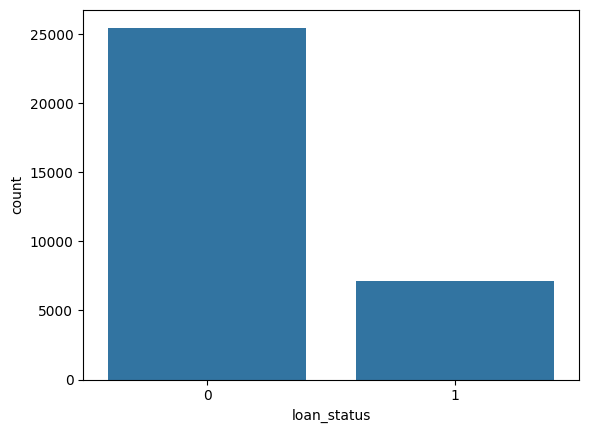

In [11]:
sns.countplot(x='loan_status', data=df)

In [12]:
(df['person_age']>100).sum()

np.int64(5)

In [13]:
(df['person_emp_length']>60).sum()

np.int64(2)

In [14]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


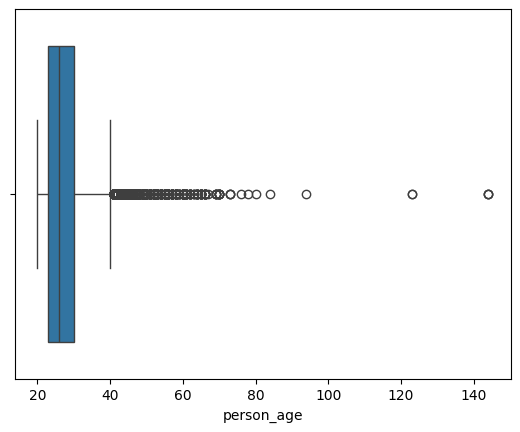

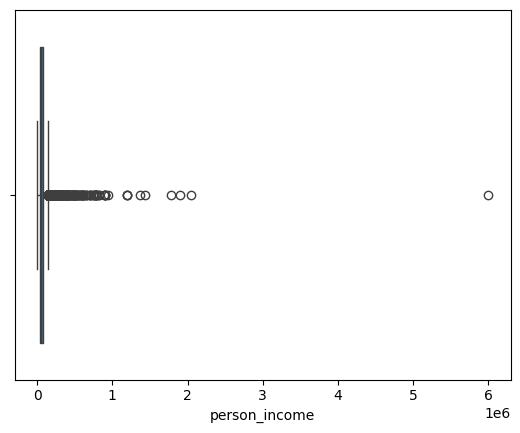

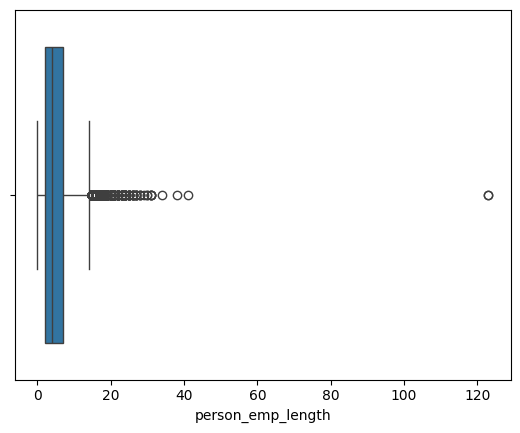

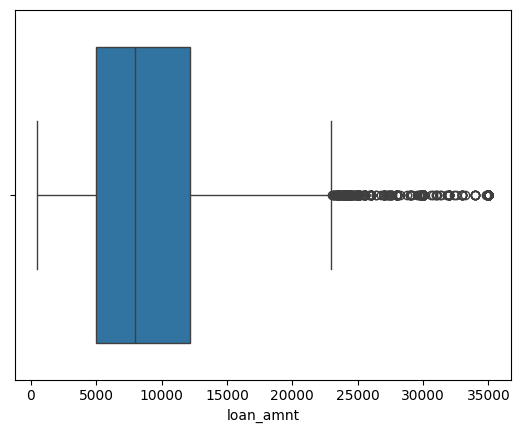

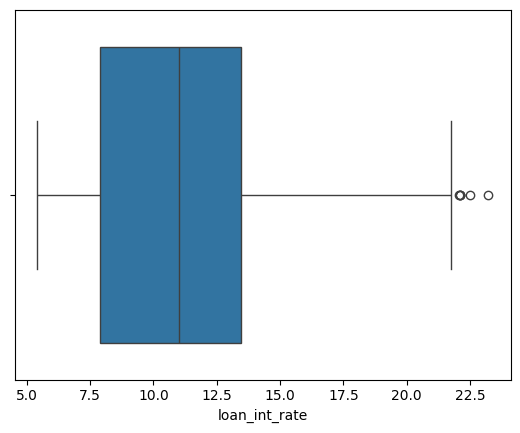

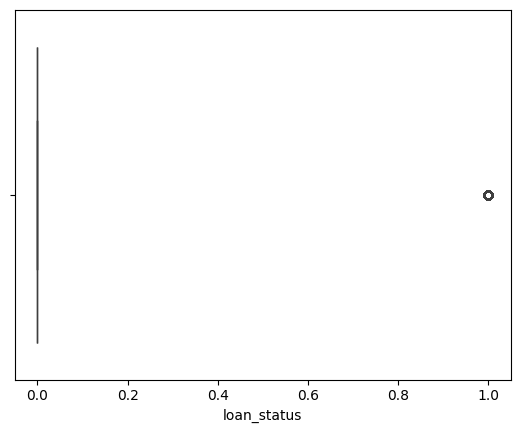

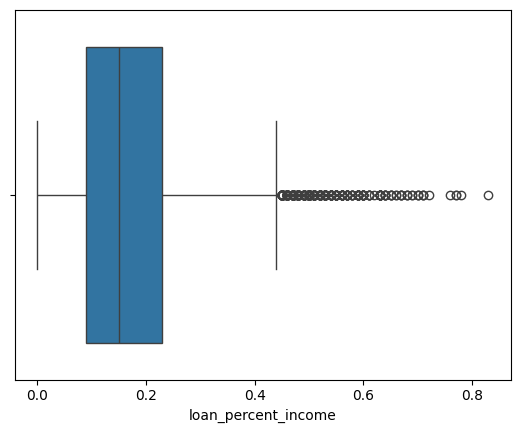

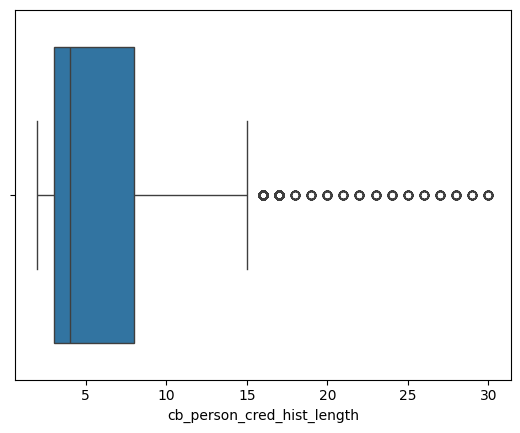

In [15]:
numerical_cols = df.select_dtypes(include="number")

for i in numerical_cols:
  sns.boxplot(x = df[i])
  plt.show()



<Axes: >

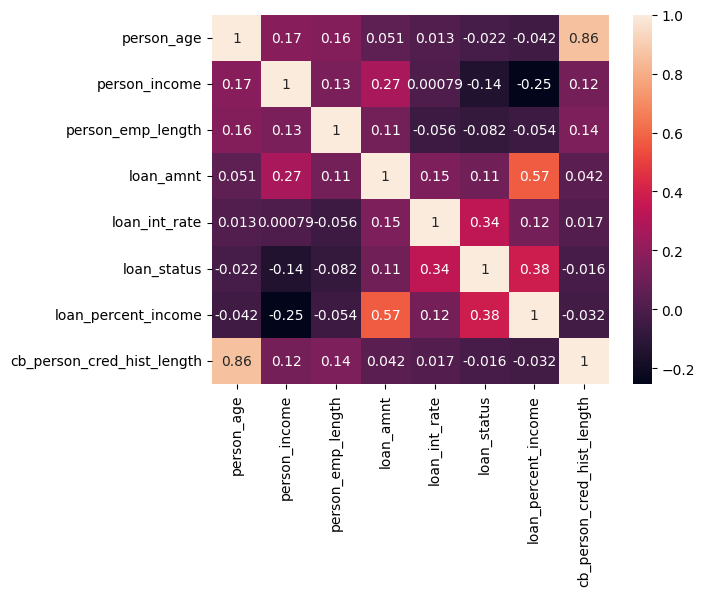

In [16]:
sns.heatmap(df.corr(numeric_only=True), annot=True)


In [17]:
df_copy = df.copy()

#remove duplicate
df_copy.drop_duplicates(inplace=True)

#remove ages below 18 or above 100
df_copy = df_copy[(df_copy['person_age']>=18) & (df_copy['person_age']<=100)]

#remove employement lenght greater than age or extreme outliers (<60)
df_copy = df_copy[(df_copy['person_emp_length']<=df_copy['person_age']) & (df_copy['person_emp_length']<=60)]

df_copy = df_copy[df_copy['loan_amnt'] > 0]






In [18]:
X = df_copy.drop('loan_status',axis=1)
y = df_copy['loan_status']

In [19]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [20]:
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                     'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


In [21]:
neg, pos = np.bincount(y_train)
scale_weights = neg/pos

In [22]:
scale_weights

np.float64(3.6312213039485766)

In [23]:
#Logistic Regression: impute + SCALE numeric, impute + One-Hot-Emcoding
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

preprocessor_lr = ColumnTransformer(
  transformers=[
    ('num', Pipeline(steps=[
      ('imputer', SimpleImputer(strategy='mean')),
      ('scaler', StandardScaler())
    ]), numeric_cols),

    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_cols)
  ])



In [24]:
#XGBoost - No scaling

preprocessor_xg = ColumnTransformer(
  transformers=[
    ('num', Pipeline(steps=[
      ('imputer', SimpleImputer(strategy='mean'))
    ]), numeric_cols),

    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_cols)
  ])



In [47]:
#   Evaluate Function MODEL
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, precision_recall_curve
def evaluate_model(model_name, model, X_test, y_test, threshold=None):

  y_pred_proba = model.predict_proba(X_test)[:,1]

  if threshold is not None:
    y_pred = (y_pred_proba >= threshold).astype(int)
  else:
    y_pred = model.predict(X_test)

  #Metrices
  accuracy = accuracy_score(y_test, y_pred)
  precision = precision_score(y_test, y_pred)
  recall = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)
  roc_auc = roc_auc_score(y_test, y_pred_proba)


  #Confusion Matrix
  conf_matrix = confusion_matrix(y_test, y_pred)

  #Classification Report
  class_report = classification_report(y_test, y_pred)
  print(model_name)
  print(f'Accuracy: {accuracy:.2f}')
  print(f'Best Threshold: {threshold}')
  print(f'Precision: {precision:.2f}')
  print(f'Recall: {recall:.2f}')
  print(f'F1: {f1:.2f}')
  print(f'ROC AUC: {roc_auc:.2f}')
  print()
  print(class_report)

  sns.heatmap(conf_matrix, annot=True, fmt='d')
  plt.title(f'{model_name} Confusion Matrix')
  plt.xlabel('Predicted')
  plt.ylabel('Actual')
  plt.show()

  precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba)
  plt.plot(recalls, precisions, label=f'{model_name} Precision-Recall Curve')
  plt.xlabel('Recall')
  plt.ylabel('Precision')
  plt.title(f'{model_name} Precision-Recall Curve')
  plt.legend()




In [26]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy',
    'f1': 'f1',
    'precision': 'precision',
    'recall': 'recall'
}

In [27]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
lr_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [28]:
#XGBoost
from xgboost import XGBClassifier
xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        n_estimator=300,
        scale_pos_weight=scale_weights,
        random_state=42,
        learning_rate=0.1))
])

xgb_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   O...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimator=300, n_estimators=None, n_jobs=None, ...))])

In [29]:
for cv_name, pipe in [('Logistic Regression', lr_cv_pipeline), ('XGBoost', xgb_cv_pipeline)]:

  cv_results = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

  print(cv_name)
  print('ROC AUC: ', cv_results['test_roc_auc'].mean())
  print('Accuracy: ', cv_results['test_accuracy'].mean())
  print('F1: ', cv_results['test_f1'].mean())
  print('Precision: ', cv_results['test_precision'].mean())
  print('Recall: ', cv_results['test_recall'].mean())
  print()





Logistic Regression
ROC AUC:  0.8705017162553327
Accuracy:  0.8116346210849974
F1:  0.6409531225245716
Precision:  0.544857346045846
Recall:  0.7785123966942149

XGBoost
ROC AUC:  0.9417709191992494
Accuracy:  0.9169210295031327
F1:  0.8032746170185352
Precision:  0.8222662747176978
Recall:  0.7856749311294766



In [30]:
baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(class_weight='balanced'))
])

baseline_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

Baseline Model
Accuracy: 0.82
Precision: 0.56
Recall: 0.79
F1: 0.65
ROC AUC: 0.88

              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



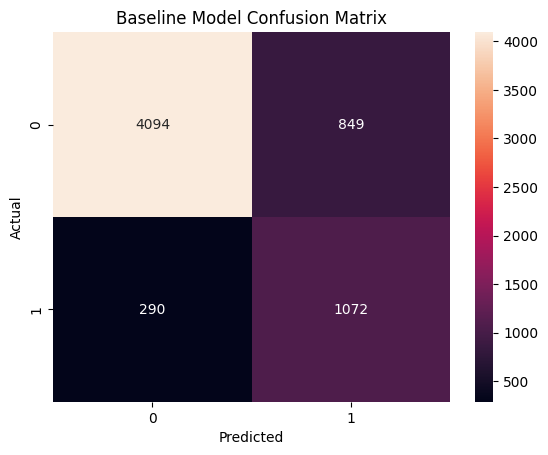

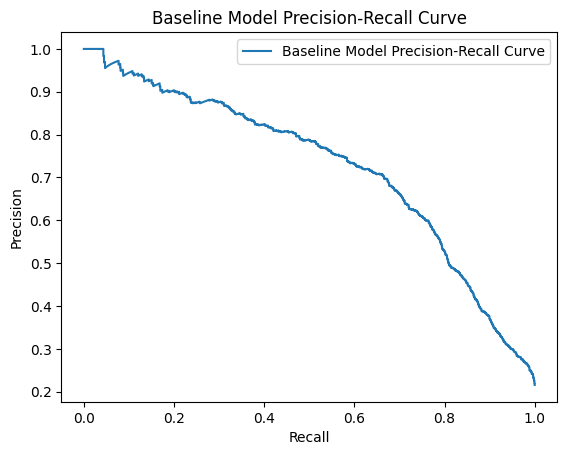

In [31]:
#Evaluating
evaluate_model('Baseline Model', baseline_model, X_test, y_test)

In [32]:
xg_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        scale_pos_weight=scale_weights,
        random_state=42,
        learning_rate=0.1))
])

xg_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   O...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

XGBoost
Accuracy: 0.92
Precision: 0.82
Recall: 0.79
F1: 0.80
ROC AUC: 0.95

              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4943
           1       0.82      0.79      0.80      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.88      6305
weighted avg       0.92      0.92      0.92      6305



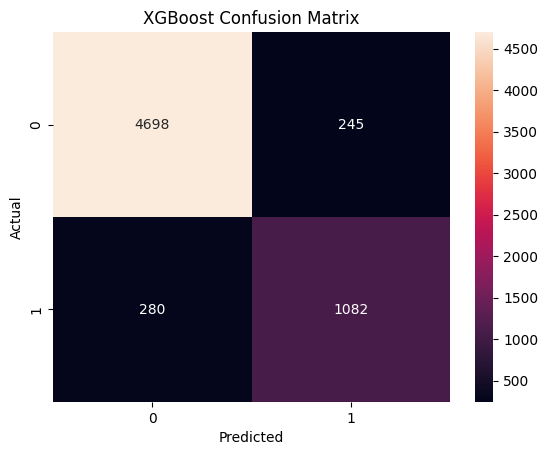

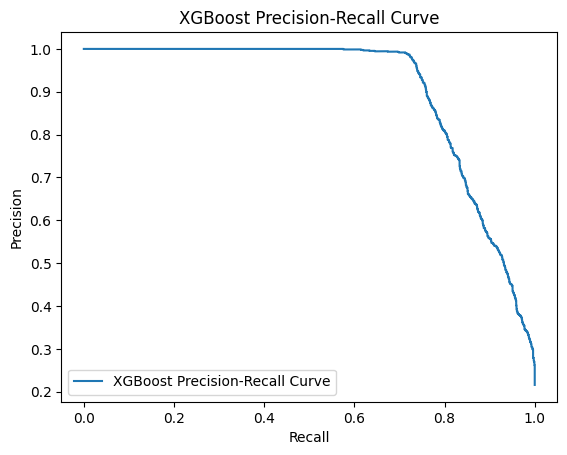

In [33]:
#Evaluate
evaluate_model('XGBoost', xg_model, X_test, y_test)

In [34]:
from scipy.stats import randint, uniform

In [35]:
from sklearn.model_selection import RandomizedSearchCV
param_grid = {
    'classifier__n_estimators': randint(150,600),
    'classifier__max_depth': randint(3,9),
    'classifier__min_child_weight': randint(1,10),
    'classifier__learning_rate': uniform(0.01,0.5),
    'classifier__subsample': uniform(0.6,0.4),
    'classifier__colsample_bytree': uniform(0.6,0.4),
    'classifier__gamma': uniform(0,5)
}


In [36]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring='average_precision',
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer())]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length']),
                                                                              ('cat',
                                                                               Pipeli...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x78402e9851d0>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x784033c23b60>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x78402e9856d0>},
                   scoring='average_precision', verbose=1)

XGBoost
Accuracy: 0.92
Precision: 0.85
Recall: 0.80
F1: 0.82
ROC AUC: 0.95

              precision    recall  f1-score   support

           0       0.95      0.96      0.95      4943
           1       0.85      0.80      0.82      1362

    accuracy                           0.92      6305
   macro avg       0.90      0.88      0.89      6305
weighted avg       0.92      0.92      0.92      6305



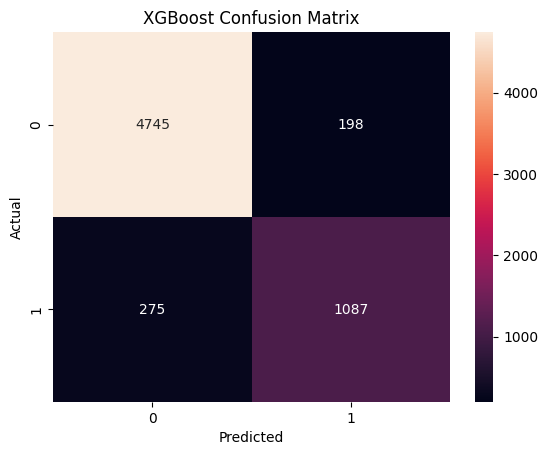

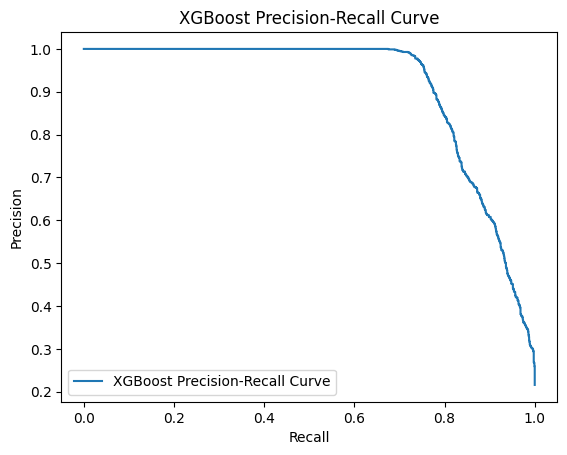

In [37]:
evaluate_model('XGBoost', random_search, X_test, y_test)

In [38]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
#import loguniform
from scipy.stats import loguniform

In [39]:
rf_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', RandomForestClassifier(
        random_state=42,
        class_weight='balanced'
    ))
])

rf_param_grid = {
    'classifier__n_estimators': randint(100, 600),
    'classifier__max_depth': [5, 10, 20, 30, 40],
    'classifier__min_samples_split': randint(2, 20),
    'classifier__min_samples_leaf': randint(1, 10),
    'classifier__max_features': ['sqrt', 'log2'],
    'classifier__class_weight': ['balanced', 'balanced_subsample']
}

rf_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=rf_param_grid,
    n_iter=40,
    scoring='average_precision',
    n_jobs=-1,
    random_state=42,
    verbose=1,
    refit=True
)

rf_search.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_search.best_params_)

print("Best CV Average Precision:")
print(rf_search.best_score_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best Random Forest parameters:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 20, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 6, 'classifier__n_estimators': 589}
Best CV Average Precision:
0.8822815048563191


Random Forest
Accuracy: 0.93
Precision: 0.96
Recall: 0.73
F1: 0.83
ROC AUC: 0.94

              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4943
           1       0.96      0.73      0.83      1362

    accuracy                           0.93      6305
   macro avg       0.94      0.86      0.89      6305
weighted avg       0.94      0.93      0.93      6305



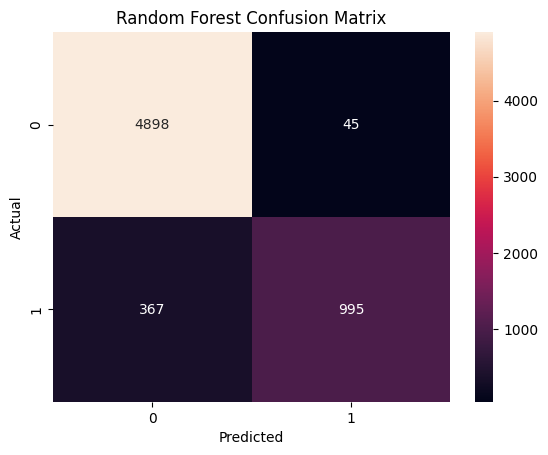

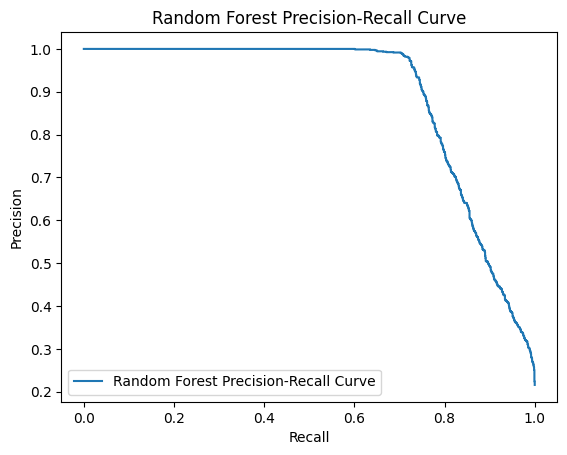

In [43]:
evaluate_model('Random Forest', rf_search, X_test, y_test)

In [42]:
ada_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=1,
            random_state=42
        ),
        random_state=42
    ))
])

ada_param_grid = {
    'classifier__n_estimators': randint(50, 500),
    'classifier__learning_rate': loguniform(0.01, 1.0),
    'classifier__estimator__max_depth': [1, 2, 3],
    'classifier__estimator__min_samples_leaf': randint(1, 10)
}

ada_search = RandomizedSearchCV(
    estimator=ada_model,
    param_distributions=ada_param_grid,
    n_iter=40,
    cv=cv,
    scoring='average_precision',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

ada_search.fit(X_train, y_train)

print("Best AdaBoost parameters:")
print(ada_search.best_params_)

print("Best CV Average Precision:")
print(ada_search.best_score_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best AdaBoost parameters:
{'classifier__estimator__max_depth': 3, 'classifier__estimator__min_samples_leaf': 4, 'classifier__learning_rate': np.float64(0.7686119654652771), 'classifier__n_estimators': 376}
Best CV Average Precision:
0.8796658344477232


AdaBoost
Accuracy: 0.92
Precision: 0.89
Recall: 0.71
F1: 0.79
ROC AUC: 0.94

              precision    recall  f1-score   support

           0       0.93      0.98      0.95      4943
           1       0.89      0.71      0.79      1362

    accuracy                           0.92      6305
   macro avg       0.91      0.84      0.87      6305
weighted avg       0.92      0.92      0.92      6305



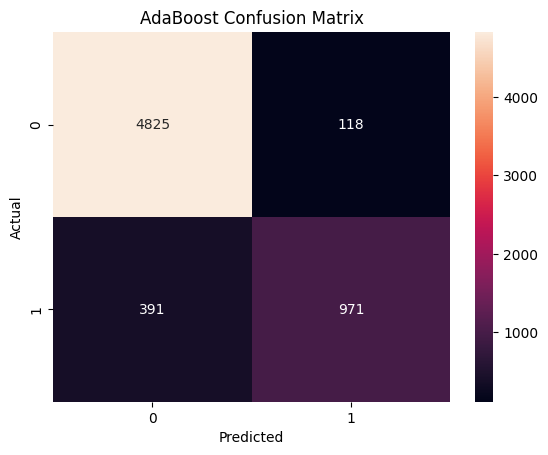

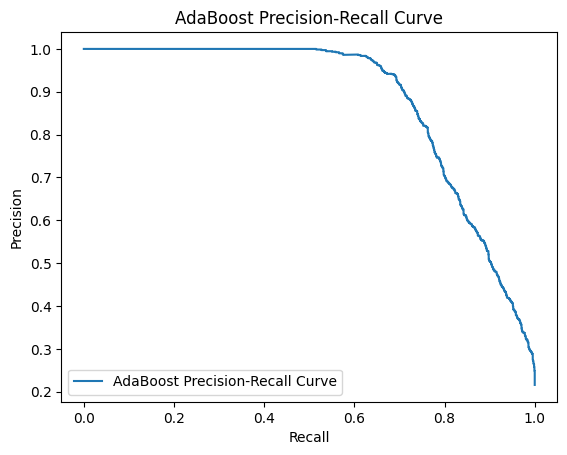

In [44]:
#evaluate
evaluate_model('AdaBoost', ada_search, X_test, y_test)

XGBoost
Accuracy: 0.94
Best Threshold: 0.7148997187614441
Precision: 0.97
Recall: 0.74
F1: 0.84
ROC AUC: 0.95

              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4943
           1       0.97      0.74      0.84      1362

    accuracy                           0.94      6305
   macro avg       0.95      0.86      0.90      6305
weighted avg       0.94      0.94      0.93      6305



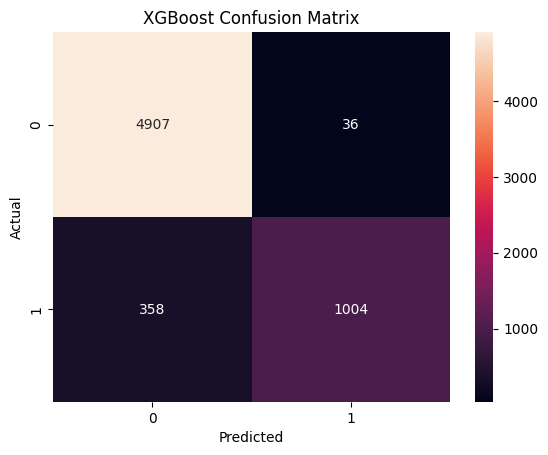

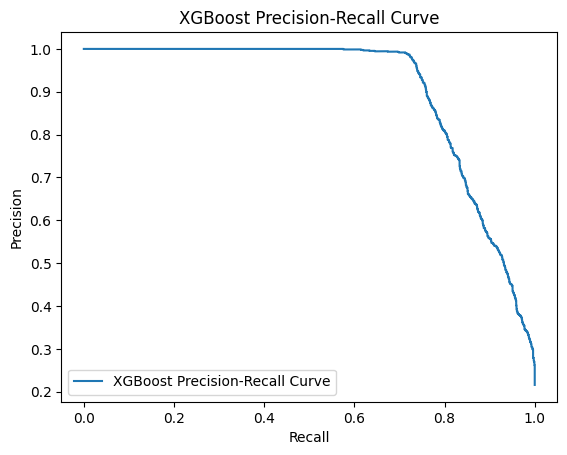

In [48]:
#Get the prob of class 1 from XGBoost
prob = xg_model.predict_proba(X_test)[:,1]

#For each threshold calculate prescision and recall
precisions, recalls, thresholds = precision_recall_curve(y_test, prob)

#Calculate F1 score for each threshold
f1 = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)
f1

#Find the threshold that maximizes F1 score
best_threshold = thresholds[np.argmax(f1[:-1])]
best_threshold

#Evaluate the XGboost with that threshold
evaluate_model('XGBoost', xg_model, X_test, y_test, best_threshold)

Random Forest
Accuracy: 0.94
Best Threshold: 0.5538979303083243
Precision: 0.98
Recall: 0.72
F1: 0.83
ROC AUC: 0.94

              precision    recall  f1-score   support

           0       0.93      1.00      0.96      4943
           1       0.98      0.72      0.83      1362

    accuracy                           0.94      6305
   macro avg       0.95      0.86      0.90      6305
weighted avg       0.94      0.94      0.93      6305



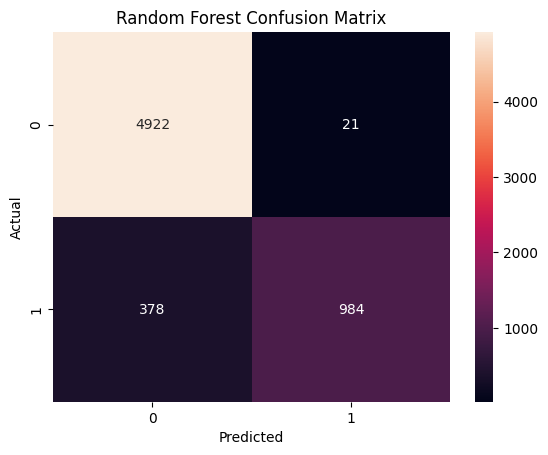

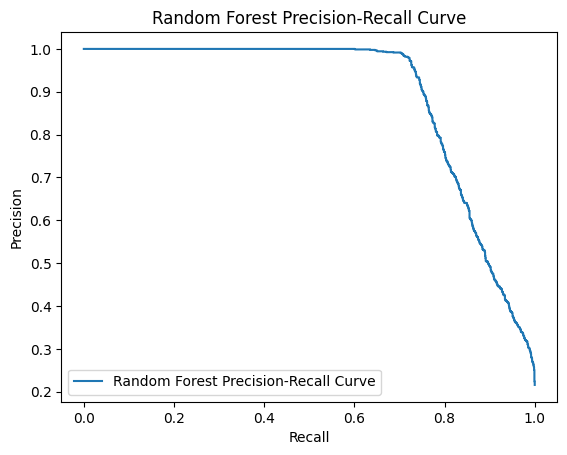

In [49]:
#Get the prob of class 1 from Randomforest
prob = rf_search.predict_proba(X_test)[:,1]

#For each threshold calculate prescision and recall
precisions, recalls, thresholds = precision_recall_curve(y_test, prob)

#Calculate F1 score for each threshold
f1 = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)
f1

#Find the threshold that maximizes F1 score
best_threshold = thresholds[np.argmax(f1[:-1])]
best_threshold

#Evaluate the RandomForest with that threshold
evaluate_model('Random Forest', rf_search, X_test, y_test, best_threshold)

In [85]:
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_model,
    cv=cv,
    method='sigmoid')
calibrated_model.fit(X_train, y_train)

CalibratedClassifierCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer())]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pi...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.05607364039701906),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=6,
                                                                max_leaves=None,
                                                                min_child_weight=1,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=446,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

In [86]:
uncalibrated = xg_model.predict_proba(X_test)[:,1]
calibrated = calibrated_model.predict_proba(X_test)[:,1]

print(calibrated)
print(uncalibrated)

[0.69433861 0.02530105 0.95425095 ... 0.52634056 0.02223362 0.01546651]
[0.89034057 0.19558865 0.97784823 ... 0.5056116  0.07657675 0.0441041 ]


In [53]:
actual_uncal, predicted_uncal = calibration_curve(y_test, uncalibrated, n_bins=10)
actual_cal, predicted_cal = calibration_curve(y_test, calibrated, n_bins=10)

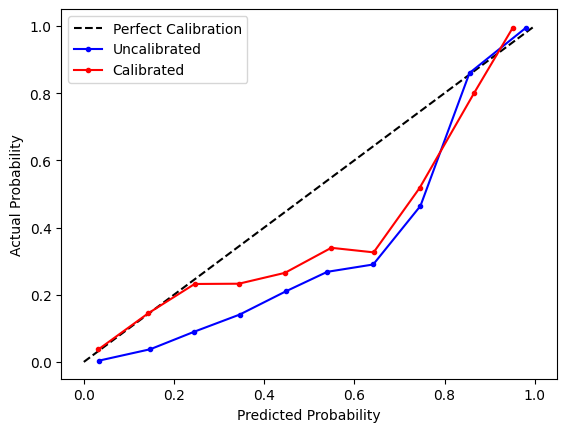

In [87]:

plt.plot([0,1], [0,1], linestyle='--', label='Perfect Calibration', color='black')
plt.xlabel('Predicted Probability')
plt.ylabel('Actual Probability')

plt.plot(
    predicted_uncal,
    actual_uncal,
    marker='.',
    color='blue',
    label='Uncalibrated'
)

plt.plot(
    predicted_cal,
    actual_cal,
    marker='.',
    color='red',
    label='Calibrated'
)

plt.legend()

In [88]:
#shap
#install shap
!pip install shap
import shap

In [89]:
#Get the Trained XGboost classifier model out of the pipeline
xgb_classifier = xg_model.named_steps['classifier']


In [90]:
#Transform X_test using the same preproceessing used for training
X_test_tranformed = xg_model.named_steps['preprocessor'].transform(X_test)

In [91]:
features_name = xg_model.named_steps['preprocessor'].get_feature_names_out()

In [92]:
X_test_df = pd.DataFrame(X_test_tranformed, columns=features_name)
X_test_df

,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OTHER,cat__person_home_ownership_OWN,...,cat__loan_intent_VENTURE,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_C,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__loan_grade_G,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
0,24.0,30000.0,1.0,15000.0,15.680000,0.50,3.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,23.0,60000.0,6.0,25600.0,11.050069,0.43,4.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,29.0,18000.0,2.0,3600.0,15.270000,0.20,6.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,32.0,130000.0,7.0,13000.0,12.690000,0.10,8.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,23.0,45288.0,7.0,20500.0,9.250000,0.45,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6300,21.0,75000.0,5.0,20000.0,13.110000,0.27,2.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
6301,29.0,265000.0,2.0,25000.0,11.260000,0.09,10.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6302,25.0,48996.0,8.0,5000.0,9.880000,0.10,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6303,27.0,115000.0,11.0,8000.0,7.510000,0.07,7.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [93]:
#creating a explainer
explainer = shap.TreeExplainer(xgb_classifier)

In [94]:
shap_values = explainer.shap_values(X_test_df)
shap_values

array([[-9.07786265e-02, -2.60130428e-02,  1.59890220e-01, ...,
        -5.71821211e-03, -2.85034254e-02,  0.00000000e+00],
       [-1.27930008e-03, -8.93621743e-01, -9.23981965e-02, ...,
        -8.82127322e-03, -1.00346413e-02,  0.00000000e+00],
       [ 8.06782246e-02,  3.55419803e+00,  7.90042803e-02, ...,
        -6.16901042e-03, -2.68914411e-03,  0.00000000e+00],
       ...,
       [ 1.61240064e-02,  5.96541762e-01,  1.09785624e-01, ...,
        -8.48879851e-03, -4.75517940e-03,  0.00000000e+00],
       [ 2.66249152e-03, -9.61422503e-01,  8.45184550e-02, ...,
        -8.81565548e-03, -5.45467064e-03,  0.00000000e+00],
       [-1.46226481e-01, -7.17261136e-01,  3.77279930e-02, ...,
        -8.21058918e-03, -3.19494843e-03,  0.00000000e+00]], dtype=float32)

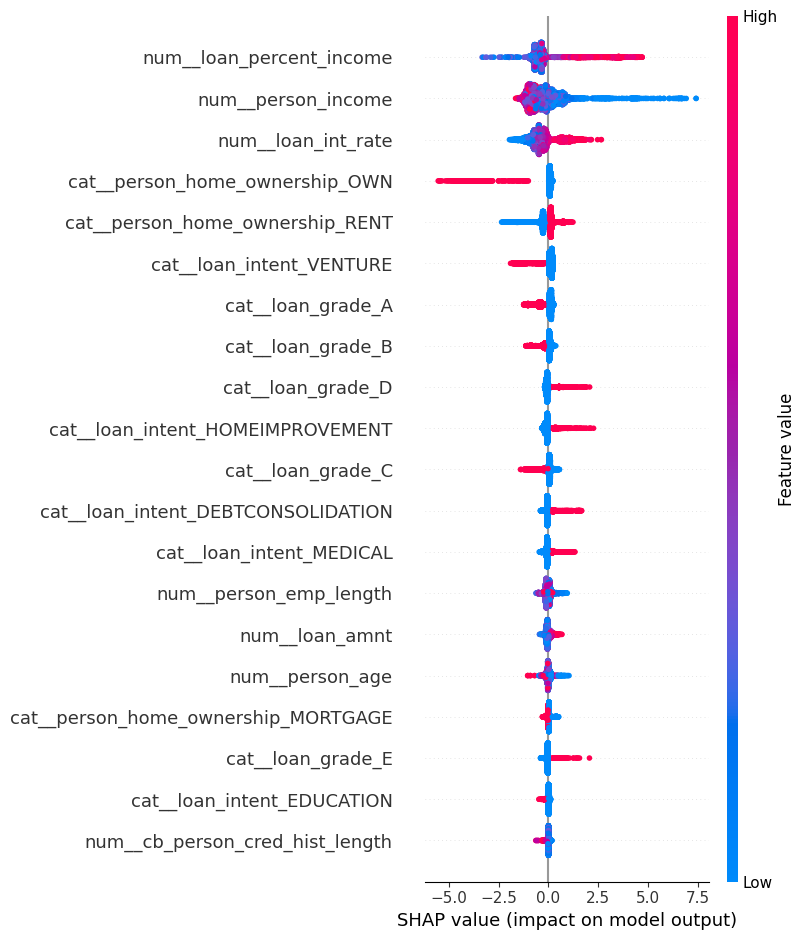

In [95]:
shap.summary_plot(shap_values, X_test_df)

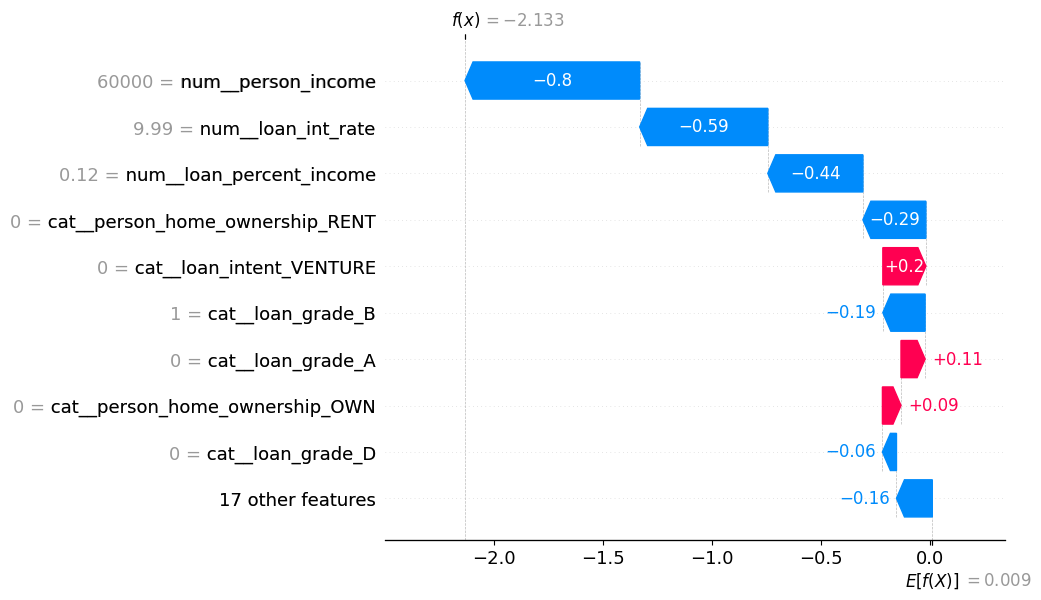

In [96]:
#pick one row to explain
row_index = 5

#draw a waterfall plot
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[row_index],
        base_values=explainer.expected_value,
        data=X_test_df.iloc[row_index],
        feature_names=X_test_df.columns
    )
)

In [97]:
#analyze false pos and false neg
y_pred = random_search.predict(X_test)


In [98]:
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred
result_df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
14455,24,30000,OWN,1.0,MEDICAL,E,15000,15.68,0.50,N,3,1,1
8701,23,60000,MORTGAGE,6.0,EDUCATION,C,25600,NaN,0.43,N,4,0,0
19804,29,18000,RENT,2.0,EDUCATION,C,3600,15.27,0.20,N,6,1,1
27252,32,130000,MORTGAGE,7.0,MEDICAL,B,13000,12.69,0.10,N,8,0,0
5610,23,45288,MORTGAGE,7.0,DEBTCONSOLIDATION,B,20500,9.25,0.45,N,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11661,21,75000,MORTGAGE,5.0,PERSONAL,C,20000,13.11,0.27,Y,2,0,0
27837,29,265000,MORTGAGE,2.0,PERSONAL,B,25000,11.26,0.09,N,10,0,0
17192,25,48996,MORTGAGE,8.0,MEDICAL,B,5000,9.88,0.10,N,2,1,1
26858,27,115000,MORTGAGE,11.0,MEDICAL,A,8000,7.51,0.07,N,7,0,0


In [99]:
#identify false pos --- model - 1 // actual - 0
false_pos = result_df[(result_df['predicted'] == 1) & (result_df['actual'] == 0)]
false_pos

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
9417,24,74000,RENT,7.0,EDUCATION,D,8000,15.62,0.11,Y,2,0,1
15993,24,52000,MORTGAGE,7.0,MEDICAL,C,5000,14.22,0.10,Y,3,0,1
17728,25,49000,MORTGAGE,9.0,PERSONAL,A,7000,6.99,0.14,N,3,0,1
7593,22,54000,MORTGAGE,4.0,EDUCATION,D,5000,15.62,0.09,N,2,0,1
28489,27,54000,MORTGAGE,1.0,HOMEIMPROVEMENT,B,27575,NaN,0.51,N,5,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6488,23,44000,RENT,2.0,MEDICAL,C,6000,14.22,0.14,Y,4,0,1
8675,23,30188,RENT,3.0,PERSONAL,C,8000,14.65,0.27,N,2,0,1
27983,27,33996,RENT,8.0,EDUCATION,D,6000,15.31,0.18,N,10,0,1
31770,38,140000,MORTGAGE,1.0,PERSONAL,D,10000,14.09,0.07,N,16,0,1


In [100]:
#identify false neg --- model - 0 // actual - 1
false_neg = result_df[(result_df['predicted'] == 0) & (result_df['actual'] == 1)]
false_neg

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
8642,23,53950,MORTGAGE,8.0,EDUCATION,E,15000,16.63,0.28,Y,2,1,0
5615,23,39325,MORTGAGE,3.0,EDUCATION,C,2800,12.87,0.07,N,4,1,0
23959,35,62000,MORTGAGE,9.0,HOMEIMPROVEMENT,B,13000,9.25,0.21,N,10,1,0
4305,23,52000,RENT,5.0,PERSONAL,D,4600,14.96,0.09,N,2,1,0
2584,25,29000,RENT,9.0,MEDICAL,A,3000,6.62,0.10,N,2,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
27976,32,31000,RENT,0.0,EDUCATION,B,5000,11.49,0.16,N,8,1,0
10520,26,52703,MORTGAGE,5.0,MEDICAL,B,4000,11.89,0.06,N,4,1,0
19389,34,30857,RENT,6.0,VENTURE,C,3000,13.06,0.10,N,9,1,0
4105,22,22560,RENT,3.0,PERSONAL,D,4200,15.20,0.19,Y,4,1,0


In [101]:
print(f'False Positive: {len(false_pos)}')
print(f'False Negative: {len(false_neg)}')

False Positive: 198
False Negative: 275


In [102]:
import joblib
joblib.dump(calibrated_model, 'calibrated_model.pkl')

['calibrated_model.pkl']

In [103]:
joblib.dump(best_threshold, 'best_threshold.pkl')

['best_threshold.pkl']